<a href="https://colab.research.google.com/github/nipun-19/ml/blob/main/Simple_and_Multiple_Linear_Regression_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment: Simple and Multiple Linear Regression

**Aim:** To implement Simple Linear Regression using NumPy and Multiple Linear Regression using Scikit-learn, plot regression results and residuals, and calculate RMSE and R².

**Software required:** Python, NumPy, Matplotlib, Scikit-learn

**Learning outcomes:**
- Understand simple and multiple linear regression.
- Fit a regression model and predict output values.
- Visualize actual values, predicted values and residuals.
- Evaluate a regression model using RMSE and R².

>


## Part A: Simple Linear Regression using NumPy

In simple linear regression, one input variable (X) is used to predict one output variable (Y).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Input data
X = np.array([1, 2, 3, 4, 5])
Y = np.array([20, 30, 40, 50, 60])

# Find slope and intercept
slope, intercept = np.polyfit(X, Y, 1)

# Predict Y values
Y_pred = slope * X + intercept

# Calculate RMSE
rmse = np.sqrt(np.mean((Y - Y_pred) ** 2))

# Calculate R-squared
ss_total = np.sum((Y - np.mean(Y)) ** 2)
ss_error = np.sum((Y - Y_pred) ** 2)
r2 = 1 - (ss_error / ss_total)

print("Slope:", slope)
print("Intercept:", intercept)
print("Predicted values:", Y_pred)
print("RMSE:", rmse)
print("R-squared:", r2)

Slope: 10.0
Intercept: 10.0
Predicted values: [20. 30. 40. 50. 60.]
RMSE: 0.0
R-squared: 1.0


### Plot regression line and residuals

A residual is the difference between an actual value and its predicted value. The vertical dashed lines show these residuals.

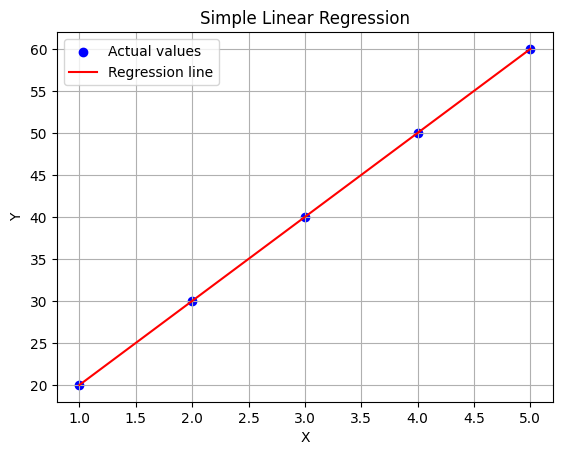

In [2]:
plt.scatter(X, Y, color="blue", label="Actual values")
plt.plot(X, Y_pred, color="red", label="Regression line")

# Show residuals
for i in range(len(X)):
    plt.plot([X[i], X[i]], [Y[i], Y_pred[i]], "k--")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid()
plt.show()

### Expected result

- Slope = 10
- Intercept = 10
- Predicted values = [20, 30, 40, 50, 60]
- RMSE = 0
- R² = 1

The data points lie exactly on the regression line, so the prediction error is zero.


## Part B: Multiple Linear Regression using Scikit-learn

Multiple linear regression uses two or more input variables to predict one output variable. Here, marks are predicted using study hours and attendance.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Input data: [Study Hours, Attendance]
X = np.array([
    [1, 60],
    [2, 65],
    [3, 70],
    [4, 75],
    [5, 80],
    [6, 85],
    [7, 90]
])

# Output data: Marks
Y = np.array([40, 45, 50, 55, 65, 70, 80])

# Create and train the model
model = LinearRegression()
model.fit(X, Y)

# Predict marks
Y_pred = model.predict(X)

# Calculate RMSE and R-squared
rmse = np.sqrt(mean_squared_error(Y, Y_pred))
r2 = r2_score(Y, Y_pred)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)
print("Predicted marks:", Y_pred)
print("RMSE:", rmse)
print("R-squared:", r2)

Intercept: -38.454670329670286
Coefficients: [0.25412088 1.2706044 ]
Predicted marks: [38.03571429 44.64285714 51.25       57.85714286 64.46428571 71.07142857
 77.67857143]
RMSE: 1.7127969726116865
R-squared: 0.9834770114942528


### Plot actual and predicted values

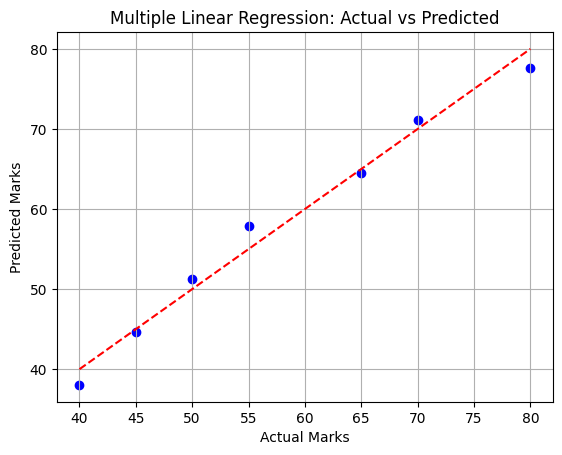

In [4]:
plt.scatter(Y, Y_pred, color="blue")
plt.plot([min(Y), max(Y)], [min(Y), max(Y)], "r--")

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.grid()
plt.show()

### Plot residuals

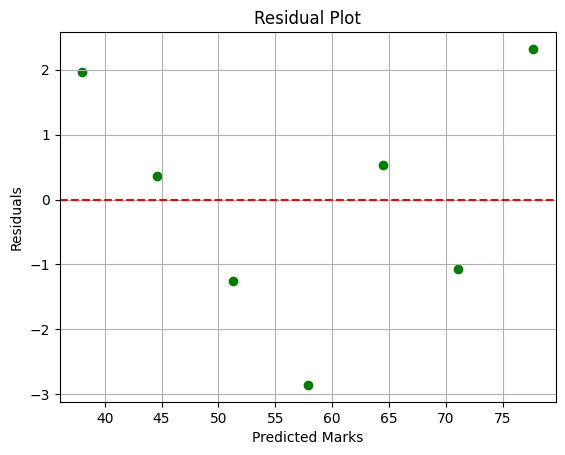

In [5]:
residuals = Y - Y_pred

plt.scatter(Y_pred, residuals, color="green")
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Marks")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid()
plt.show()

## Additional Example: Predict House Price from Area

A new real-life example of simple linear regression. The price (in lakhs) depends on the house area (in square feet). Noise is added so that the points do not lie exactly on a line, and we predict the price of a new house.

Slope (price per sq. ft, lakhs): 0.0423
Intercept: 0.56
RMSE: 1.238
R-squared: 0.9977


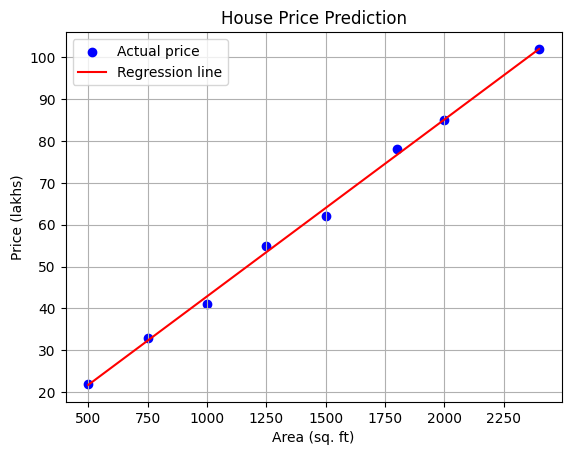

Predicted price for 1650 sq. ft: 70.32 lakhs


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Area (sq. ft) and Price (lakhs)
area = np.array([500, 750, 1000, 1250, 1500, 1800, 2000, 2400]).reshape(-1, 1)
price = np.array([22, 33, 41, 55, 62, 78, 85, 102])

house_model = LinearRegression()
house_model.fit(area, price)
price_pred = house_model.predict(area)

print("Slope (price per sq. ft, lakhs):", round(house_model.coef_[0], 4))
print("Intercept:", round(house_model.intercept_, 2))
print("RMSE:", round(np.sqrt(mean_squared_error(price, price_pred)), 3))
print("R-squared:", round(r2_score(price, price_pred), 4))

plt.scatter(area, price, color="blue", label="Actual price")
plt.plot(area, price_pred, color="red", label="Regression line")
plt.xlabel("Area (sq. ft)")
plt.ylabel("Price (lakhs)")
plt.title("House Price Prediction")
plt.legend()
plt.grid()
plt.show()

new_area = np.array([[1650]])
print("Predicted price for 1650 sq. ft:",
      round(house_model.predict(new_area)[0], 2), "lakhs")

**Observation:** The slope shows how much the price increases for each extra square foot. Unlike Part A, the points are not exactly on the line, so RMSE is above 0 and R² is slightly below 1.

## Observations

1. Simple Linear Regression uses one independent variable.
2. Multiple Linear Regression uses more than one independent variable.
3. The regression line represents the relationship between input and output.
4. Residuals show the difference between actual and predicted values.
5. Lower RMSE indicates smaller prediction errors.
6. R² closer to 1 indicates that the model explains more variation in the output.

## Result

Simple Linear Regression was implemented using NumPy and Multiple Linear Regression was implemented using Scikit-learn. Regression plots and residual plots were generated, and model performance was evaluated using RMSE and R².
